# Toxoplasma gondii seropositivity: data and model accuracy

**Dataset:** NHANES 2013-2014 adults (`data/processed/nhanes_adult_toxo_clean.csv`, built by `scripts/cleaning2.py`)
**Target:** `target_toxo_pos` = 1 if Toxoplasma IgG ≥ 33 IU/mL
**Model code:** `scripts/train_baseline.py` (unchanged; this notebook runs it and builds on its results)

Contents
1. **The data**: every column, missing values, class balance, positivity rate by group
2. **Full output of the current training script** (`train_baseline.py`)
3. **The three feature sets** (A demographics, B + Toxocara, C all): cross-validation results for each, fold by fold
4. **Accuracy**: cross-validated accuracy, then the held-out **test set** (accuracy, sensitivity, specificity, confusion matrices), plus **ROC curves and AUC** for every model (4.5)
5. **Total accuracy summary**

In [19]:
import os
import warnings

# The notebook lives in research_r/; all project paths are relative to the repo root
if os.path.basename(os.getcwd()) == 'research_r':
    os.chdir('..')
print('Working directory:', os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             brier_score_loss, classification_report, confusion_matrix,
                             make_scorer, precision_score, roc_auc_score, roc_curve)
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)
pd.set_option('display.max_rows', 200)

# Chart style: recessive grid/axes, neutral ink for text, fixed colours per feature set
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
SET_COLORS = {'A_demographics': '#2a78d6', 'B_demo_toxocara': '#eb6834', 'C_all': '#1baf7a'}
SINGLE = '#2a78d6'
REFERENCE = '#8a8985'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'text.color': INK,
    'font.size': 10, 'legend.frameon': False, 'figure.dpi': 110,
})

Working directory: /Users/richard/Documents/Binus/Semester 5/toxoplasma-research


---
## 1. The data

In [20]:
DATA_CSV = os.path.join('data', 'processed', 'nhanes_adult_toxo_clean.csv')
data = pd.read_csv(DATA_CSV)
print(f'File: {DATA_CSV}')
print(f'Rows (participants): {data.shape[0]:,}')
print(f'Columns:             {data.shape[1]}')

File: data/processed/nhanes_adult_toxo_clean.csv
Rows (participants): 5,006
Columns:             19


### 1.1 First 20 rows

In [21]:
display(data.head(20))

,SEQN,RIDAGEYR,RIAGENDR,RIDRETH3,DMDBORN4,DMDEDUC2,INDFMPIR,WTMEC2YR,SDMVPSU,SDMVSTRA,HSD010,SLD010H,SLQ050,smoking_status,drinks_per_day,yrs_in_us_grp,toxocara_pos,phq9_total_score,target_toxo_pos
0,73557.0,69.0,1.0,4.0,1.0,3.0,0.84,13481.042095,1.0,112.0,2.0,7.0,1.0,1.0,1.0,0.0,1,1.0,0
1,73558.0,54.0,1.0,3.0,1.0,3.0,1.78,24471.769625,1.0,108.0,4.0,9.0,2.0,2.0,4.0,0.0,0,2.0,0
2,73561.0,73.0,2.0,3.0,1.0,5.0,5.00,65541.871229,2.0,116.0,5.0,9.0,2.0,0.0,0.0,0.0,0,9.0,0
3,73562.0,56.0,1.0,1.0,1.0,4.0,4.79,25344.992359,1.0,111.0,5.0,5.0,2.0,1.0,1.0,0.0,0,19.0,1
4,73564.0,61.0,2.0,3.0,1.0,5.0,5.00,61758.654880,1.0,114.0,3.0,9.0,2.0,0.0,1.0,0.0,0,2.0,0
5,73566.0,56.0,2.0,3.0,1.0,3.0,0.48,17480.115175,1.0,112.0,3.0,6.0,1.0,2.0,1.0,0.0,0,1.0,0
6,73567.0,65.0,1.0,3.0,1.0,2.0,1.20,34795.429301,2.0,112.0,3.0,7.0,2.0,2.0,3.0,0.0,0,3.0,0
7,73568.0,26.0,2.0,3.0,1.0,5.0,5.00,91523.516048,2.0,113.0,1.0,8.0,2.0,0.0,2.0,0.0,0,0.0,0
8,73571.0,76.0,1.0,3.0,1.0,5.0,5.00,46190.114005,1.0,116.0,3.0,6.0,1.0,0.0,1.0,0.0,0,6.0,0
9,73577.0,32.0,1.0,1.0,2.0,1.0,0.29,39735.017070,2.0,118.0,3.0,8.0,2.0,1.0,15.0,2.0,0,1.0,0


### 1.2 Last 10 rows

In [23]:
display(data.tail(10))

,SEQN,RIDAGEYR,RIAGENDR,RIDRETH3,DMDBORN4,DMDEDUC2,INDFMPIR,WTMEC2YR,SDMVPSU,SDMVSTRA,HSD010,SLD010H,SLQ050,smoking_status,drinks_per_day,yrs_in_us_grp,toxocara_pos,phq9_total_score,target_toxo_pos
4996,83712.0,61.0,1.0,3.0,1.0,2.0,2.04,38231.457622,2.0,115.0,3.0,7.0,2.0,0.0,1.0,0.0,0,3.0,1
4997,83713.0,34.0,1.0,6.0,2.0,4.0,1.27,16535.236604,2.0,118.0,NaN,5.0,1.0,0.0,NaN,2.0,0,NaN,0
4998,83714.0,19.0,2.0,3.0,1.0,3.0,1.20,26632.551922,1.0,114.0,NaN,7.0,2.0,2.0,NaN,0.0,0,NaN,0
4999,83715.0,58.0,1.0,3.0,1.0,1.0,0.94,27756.512614,2.0,116.0,2.0,6.0,1.0,2.0,0.0,0.0,0,8.0,1
5000,83717.0,80.0,2.0,1.0,2.0,1.0,0.70,12031.439724,1.0,107.0,4.0,8.0,2.0,0.0,0.0,3.0,1,9.0,1
5001,83721.0,52.0,1.0,3.0,2.0,5.0,5.00,68456.771849,1.0,112.0,2.0,8.0,2.0,0.0,1.0,1.0,1,0.0,0
5002,83723.0,61.0,1.0,1.0,1.0,2.0,3.53,11179.994842,1.0,109.0,4.0,6.0,2.0,0.0,2.0,0.0,1,0.0,0
5003,83724.0,80.0,1.0,3.0,1.0,3.0,3.09,29383.486541,1.0,117.0,2.0,9.0,1.0,1.0,0.0,0.0,0,1.0,1
5004,83727.0,26.0,1.0,2.0,1.0,5.0,NaN,28115.568221,1.0,104.0,3.0,7.0,2.0,0.0,3.0,0.0,0,0.0,0
5005,83729.0,42.0,2.0,4.0,2.0,5.0,3.66,26902.344381,1.0,104.0,NaN,7.0,2.0,0.0,NaN,3.0,0,NaN,1


### 1.3 Column dictionary
Role tells you how `train_baseline.py` uses each column. Missing values are imputed inside the model pipeline. They are not dropped.

In [24]:
COLUMN_INFO = {
    'SEQN':             ('ID (not a feature)',          'Participant sequence number'),
    'RIDAGEYR':         ('Feature: demographics',       'Age in years (18-80, 80 = 80+)'),
    'RIAGENDR':         ('Feature: demographics',       'Sex: 1 = male, 2 = female'),
    'RIDRETH3':         ('Feature: demographics',       'Race/Hispanic origin: 1 Mexican American, 2 Other Hispanic, 3 NH White, 4 NH Black, 6 NH Asian, 7 Other/multi'),
    'DMDBORN4':         ('Not used (dup. of yrs_in_us)', 'Country of birth: 1 = US, 2 = elsewhere'),
    'DMDEDUC2':         ('Feature: demographics',       'Education 1-5: <9th grade ... college graduate'),
    'INDFMPIR':         ('Feature: demographics',       'Family income-to-poverty ratio (0-5)'),
    'WTMEC2YR':         ('Survey design (not a feature)', 'MEC exam sample weight'),
    'SDMVPSU':          ('Survey design (not a feature)', 'Masked variance PSU'),
    'SDMVSTRA':         ('Survey design (not a feature)', 'Masked variance stratum'),
    'HSD010':           ('Feature: behaviour/health',   'Self-rated general health: 1 excellent ... 5 poor'),
    'SLD010H':          ('Feature: behaviour/health',   'Usual sleep hours on workdays'),
    'SLQ050':           ('Feature: behaviour/health',   'Ever told a doctor about trouble sleeping: 1 yes, 2 no'),
    'smoking_status':   ('Feature: behaviour/health',   '0 never, 1 former, 2 current smoker'),
    'drinks_per_day':   ('Feature: behaviour/health',   'Average drinks per drinking day (0 = non-drinker)'),
    'yrs_in_us_grp':    ('Feature: demographics',       '0 US-born, 1 <10 yrs in US, 2 10-19 yrs, 3 20+ yrs, 4 foreign-born/unknown'),
    'toxocara_pos':     ('Feature: Toxocara',           'Toxocara antibody: 1 positive, 0 negative'),
    'phq9_total_score': ('Feature: behaviour/health',   'PHQ-9 depression score (0-27)'),
    'target_toxo_pos':  ('TARGET',                      'Toxoplasma IgG >= 33 IU/mL: 1 positive, 0 negative'),
}
dictionary = pd.DataFrame([{
    'column': c,
    'role': COLUMN_INFO[c][0],
    'meaning': COLUMN_INFO[c][1],
    'dtype': str(data[c].dtype),
    'missing': int(data[c].isna().sum()),
    'missing %': round(data[c].isna().mean() * 100, 1),
    'unique values': int(data[c].nunique()),
    'min': data[c].min(),
    'max': data[c].max(),
} for c in data.columns])
display(dictionary)

,column,role,meaning,dtype,missing,missing %,unique values,min,max
0,SEQN,ID (not a feature),Participant sequence number,float64,0,0.0,5006,73557.000000,83729.000000
1,RIDAGEYR,Feature: demographics,"Age in years (18-80, 80 = 80+)",float64,0,0.0,63,18.000000,80.000000
2,RIAGENDR,Feature: demographics,"Sex: 1 = male, 2 = female",float64,0,0.0,2,1.000000,2.000000
3,RIDRETH3,Feature: demographics,"Race/Hispanic origin: 1 Mexican American, 2 Ot...",float64,0,0.0,6,1.000000,7.000000
4,DMDBORN4,Not used (dup. of yrs_in_us),"Country of birth: 1 = US, 2 = elsewhere",float64,1,0.0,2,1.000000,2.000000
5,DMDEDUC2,Feature: demographics,Education 1-5: <9th grade ... college graduate,float64,4,0.1,5,1.000000,5.000000
6,INDFMPIR,Feature: demographics,Family income-to-poverty ratio (0-5),float64,361,7.2,413,0.000000,5.000000
7,WTMEC2YR,Survey design (not a feature),MEC exam sample weight,float64,0,0.0,4474,5751.715759,171395.264901
8,SDMVPSU,Survey design (not a feature),Masked variance PSU,float64,0,0.0,2,1.000000,2.000000
9,SDMVSTRA,Survey design (not a feature),Masked variance stratum,float64,0,0.0,15,104.000000,118.000000


### 1.4 Summary statistics (all columns)

In [25]:
display(data.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
SEQN,5006.0,78686.50,2907.91,73557.00,76191.50,78717.00,81173.75,83729.00
RIDAGEYR,5006.0,47.99,18.40,18.00,32.00,47.00,63.00,80.00
RIAGENDR,5006.0,1.53,0.50,1.00,1.00,2.00,2.00,2.00
RIDRETH3,5006.0,3.25,1.50,1.00,3.00,3.00,4.00,7.00
DMDBORN4,5005.0,1.28,0.45,1.00,1.00,1.00,2.00,2.00
DMDEDUC2,5002.0,3.49,1.22,1.00,3.00,4.00,4.00,5.00
INDFMPIR,4645.0,2.49,1.64,0.00,1.04,2.10,4.03,5.00
WTMEC2YR,5006.0,41400.45,31376.94,5751.72,19029.74,28525.31,56424.04,171395.26
SDMVPSU,5006.0,1.48,0.50,1.00,1.00,1.00,2.00,2.00
SDMVSTRA,5006.0,110.94,4.31,104.00,107.00,111.00,115.00,118.00


### 1.5 Value counts of every coded (categorical) column

In [26]:
CODED = ['RIAGENDR', 'RIDRETH3', 'DMDBORN4', 'yrs_in_us_grp', 'DMDEDUC2', 'HSD010',
         'SLQ050', 'smoking_status', 'toxocara_pos', 'target_toxo_pos']
for col in CODED:
    vc = data[col].value_counts(dropna=False).sort_index()
    print(f'{col}  ({COLUMN_INFO[col][1]})')
    print(pd.DataFrame({'count': vc, '%': (vc / len(data) * 100).round(1)}).to_string())
    print()

RIAGENDR  (Sex: 1 = male, 2 = female)
          count     %
RIAGENDR             
1.0        2376  47.5
2.0        2630  52.5

RIDRETH3  (Race/Hispanic origin: 1 Mexican American, 2 Other Hispanic, 3 NH White, 4 NH Black, 6 NH Asian, 7 Other/multi)
          count     %
RIDRETH3             
1.0         713  14.2
2.0         450   9.0
3.0        2238  44.7
4.0         913  18.2
6.0         537  10.7
7.0         155   3.1

DMDBORN4  (Country of birth: 1 = US, 2 = elsewhere)
          count     %
DMDBORN4             
1.0        3627  72.5
2.0        1378  27.5
NaN           1   0.0

yrs_in_us_grp  (0 US-born, 1 <10 yrs in US, 2 10-19 yrs, 3 20+ yrs, 4 foreign-born/unknown)
               count     %
yrs_in_us_grp             
0.0             3627  72.5
1.0              251   5.0
2.0              371   7.4
3.0              690  13.8
4.0               66   1.3
NaN                1   0.0

DMDEDUC2  (Education 1-5: <9th grade ... college graduate)
          count     %
DMDEDUC2             

### 1.6 Class balance of the target

Negative (0): 4,256  (85.0%)
Positive (1): 750  (15.0%)

A model that always predicts "negative" already scores 85.0% accuracy.
That is the bar any accuracy number below has to be compared against.


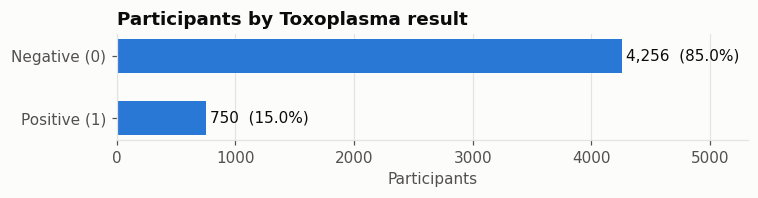

In [27]:
counts = data['target_toxo_pos'].value_counts().sort_index()
n_neg, n_pos = int(counts[0]), int(counts[1])
print(f'Negative (0): {n_neg:,}  ({n_neg / len(data):.1%})')
print(f'Positive (1): {n_pos:,}  ({n_pos / len(data):.1%})')
print(f'\nA model that always predicts "negative" already scores {n_neg / len(data):.1%} accuracy.')
print('That is the bar any accuracy number below has to be compared against.')

fig, ax = plt.subplots(figsize=(7, 1.9))
labels = ['Negative (0)', 'Positive (1)']
ax.barh(labels, [n_neg, n_pos], color=SINGLE, height=0.55)
for i, v in enumerate([n_neg, n_pos]):
    ax.text(v + 40, i, f'{v:,}  ({v / len(data):.1%})', va='center', color=INK)
ax.set_xlim(0, n_neg * 1.25)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.set_title('Participants by Toxoplasma result')
ax.set_xlabel('Participants')
plt.tight_layout()
plt.show()

### 1.7 Positivity rate by group
The share of each group that is Toxoplasma-positive. The grey line is the overall rate.

--- age_band ---
             n  positives  rate %
age_band                         
18-29     1005         69     6.9
30-39      814         89    10.9
40-49      837        123    14.7
50-59      792        127    16.0
60-69      789        147    18.6
70+        769        195    25.4

--- sex ---
           n  positives  rate %
sex                            
Male    2376        393    16.5
Female  2630        357    13.6

--- race ---
                     n  positives  rate %
race                                     
Mexican American   713        110    15.4
Other Hispanic     450        137    30.4
NH White          2238        300    13.4
NH Black           913        130    14.2
NH Asian           537         56    10.4
Other/multi        155         17    11.0

--- years_in_us ---
                     n  positives  rate %
years_in_us                              
US-born           3627        421    11.6
<10 yrs            251         66    26.3
10-19 yrs          371         

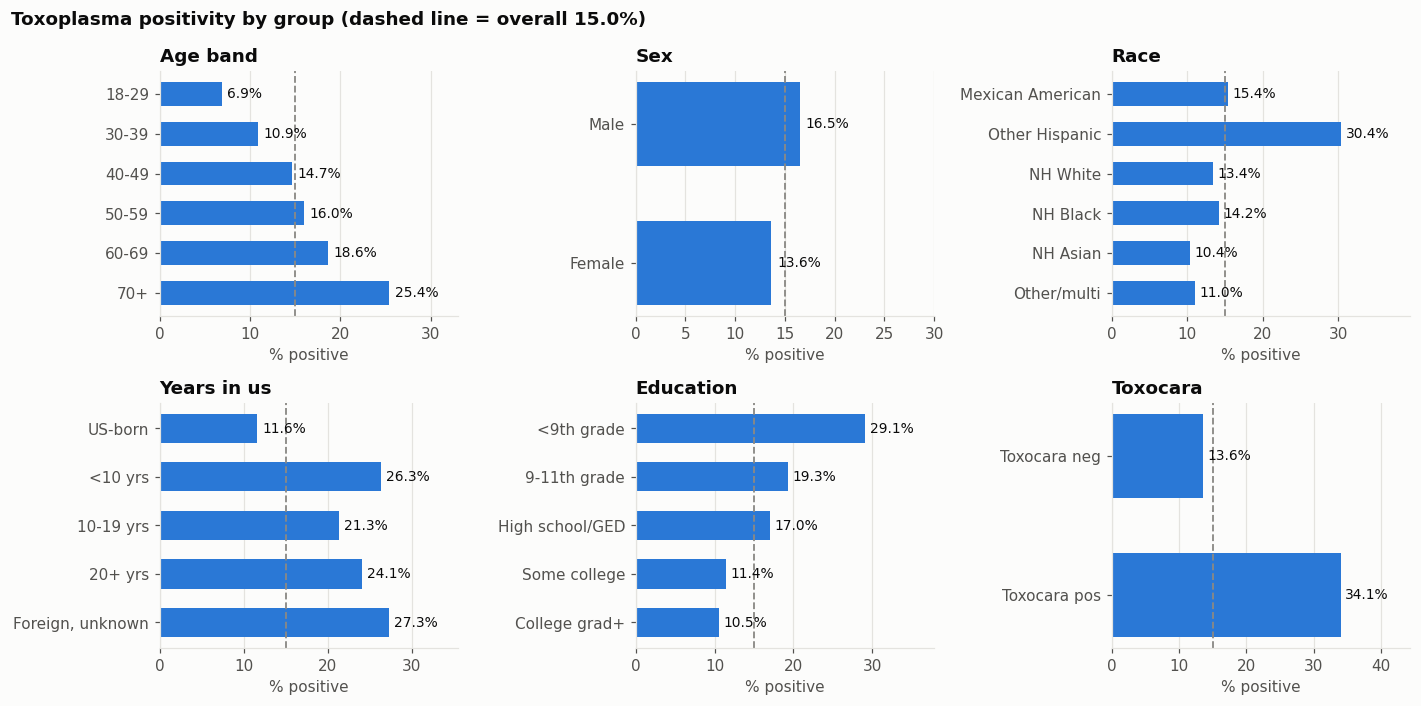

In [28]:
groups = data.assign(
    age_band=pd.cut(data['RIDAGEYR'], [17, 29, 39, 49, 59, 69, 120],
                    labels=['18-29', '30-39', '40-49', '50-59', '60-69', '70+']),
    sex=data['RIAGENDR'].map({1: 'Male', 2: 'Female'}),
    race=data['RIDRETH3'].map({1: 'Mexican American', 2: 'Other Hispanic', 3: 'NH White',
                               4: 'NH Black', 6: 'NH Asian', 7: 'Other/multi'}),
    years_in_us=data['yrs_in_us_grp'].map({0: 'US-born', 1: '<10 yrs', 2: '10-19 yrs',
                                           3: '20+ yrs', 4: 'Foreign, unknown'}),
    education=data['DMDEDUC2'].map({1: '<9th grade', 2: '9-11th grade', 3: 'High school/GED',
                                     4: 'Some college', 5: 'College grad+'}),
    toxocara=data['toxocara_pos'].map({0: 'Toxocara neg', 1: 'Toxocara pos'}),
)
ORDER = {
    'sex': ['Male', 'Female'],
    'race': ['Mexican American', 'Other Hispanic', 'NH White', 'NH Black', 'NH Asian', 'Other/multi'],
    'years_in_us': ['US-born', '<10 yrs', '10-19 yrs', '20+ yrs', 'Foreign, unknown'],
    'education': ['<9th grade', '9-11th grade', 'High school/GED', 'Some college', 'College grad+'],
    'toxocara': ['Toxocara neg', 'Toxocara pos'],
}
for col, order in ORDER.items():
    groups[col] = pd.Categorical(groups[col], categories=order, ordered=True)
GROUP_COLS = ['age_band', 'sex', 'race', 'years_in_us', 'education', 'toxocara']
overall = data['target_toxo_pos'].mean()

rate_tables = {}
for g in GROUP_COLS:
    t = (groups.groupby(g, observed=True)['target_toxo_pos']
         .agg(n='size', positives='sum', rate='mean'))
    t['rate %'] = (t.pop('rate') * 100).round(1)
    rate_tables[g] = t
    print(f'--- {g} ---')
    print(t.to_string())
    print()

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, g in zip(axes.flat, GROUP_COLS):
    t = rate_tables[g]
    ax.barh(t.index.astype(str), t['rate %'], color=SINGLE, height=0.6)
    ax.axvline(overall * 100, color=REFERENCE, lw=1.2, ls='--')
    for i, (r, n) in enumerate(zip(t['rate %'], t['n'])):
        ax.text(r + 0.6, i, f'{r:.1f}%', va='center', fontsize=9, color=INK)
    ax.invert_yaxis()
    ax.grid(axis='y', visible=False)
    ax.set_xlim(0, max(t['rate %'].max() * 1.3, 30))
    ax.set_title(g.replace('_', ' ').capitalize())
    ax.set_xlabel('% positive')
fig.suptitle(f'Toxoplasma positivity by group (dashed line = overall {overall:.1%})',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

### 1.8 Missing values per column

,missing,missing %
phq9_total_score,398,8.0
drinks_per_day,371,7.4
INDFMPIR,361,7.2
HSD010,344,6.9
SLD010H,7,0.1
DMDEDUC2,4,0.1
smoking_status,2,0.0
DMDBORN4,1,0.0
SLQ050,1,0.0
yrs_in_us_grp,1,0.0


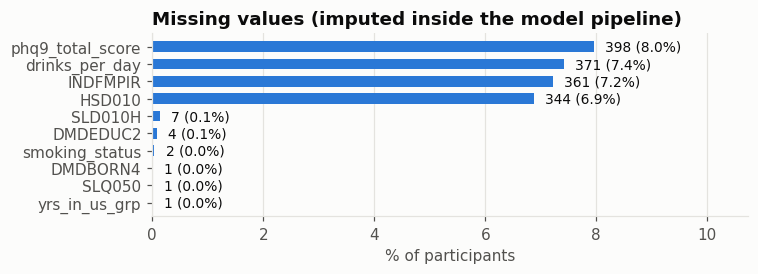

In [29]:
miss = data.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
display(pd.DataFrame({'missing': miss, 'missing %': (miss / len(data) * 100).round(1)}))

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(miss.index, miss.values / len(data) * 100, color=SINGLE, height=0.6)
for i, v in enumerate(miss.values):
    ax.text(v / len(data) * 100 + 0.2, i, f'{v} ({v / len(data):.1%})', va='center', fontsize=9)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.set_xlim(0, miss.max() / len(data) * 100 * 1.35)
ax.set_title('Missing values (imputed inside the model pipeline)')
ax.set_xlabel('% of participants')
plt.tight_layout()
plt.show()

---
## 2. Full output of the current training script
This runs `scripts/train_baseline.py` exactly as it is (about 1 minute). Everything it prints is shown below:
- train/test split
- preprocessing checks
- cross-validation results for every model and feature set
- hypothesis tests H1-H4

The script's variables (`X_train`, `X_test`, `results`, `MODELS`, `FEATURE_SETS`, ...) stay available for the rest of the notebook.

In [30]:
%run scripts/train_baseline.py

Loaded 5006 rows, 13 candidate features
Train: 4004 rows, 15.0% positive
Test:  1002 rows, 15.0% positive  (held out until the final step)

Missing values in the training set (imputed in the pipeline):
yrs_in_us_grp         1
SLQ050                1
smoking_status        2
DMDEDUC2              3
INDFMPIR            296
HSD010              272
SLD010H               6
drinks_per_day      294
phq9_total_score    317

--- Step 2 check: preprocessing fitted on the training set ---

[age_only] 1 input columns -> 1 model columns:
  num__RIDAGEYR
  missing flags match raw missing counts: 0 checked
  scaled columns mean range [-0.000, -0.000], std range [1.000, 1.000]
  one-hot blocks: exactly one level per row

[A_demographics] 6 input columns -> 16 model columns:
  cat__RIAGENDR_2.0, cat__RIDRETH3_1.0, cat__RIDRETH3_2.0, cat__RIDRETH3_3.0, cat__RIDRETH3_4.0, cat__RIDRETH3_6.0, cat__RIDRETH3_7.0, cat__yrs_in_us_grp_0.0, cat__yrs_in_us_grp_1.0, cat__yrs_in_us_grp_2.0, cat__yrs_in_us_grp_3.0, c

---
## 3. The three feature sets
Each set adds one group of features to the previous set:

| Set | Adds | Question it answers |
|---|---|---|
| **A_demographics** | age, sex, race, years in US, education, income | How far do demographics alone get us? |
| **B_demo_toxocara** | + Toxocara antibody | Does another soil/animal-exposure marker help? (H3) |
| **C_all** | + general health, sleep, smoking, alcohol, PHQ-9 | Do behaviour/health variables help? (H4) |

The same four models (LogReg, RandomForest, GradBoost, XGBoost) are trained on each set and scored on the same 15 cross-validation folds (5-fold × 3 repeats, training set only).

In [31]:
THREE_SETS = ['A_demographics', 'B_demo_toxocara', 'C_all']
display(pd.DataFrame([{
    'feature set': s,
    'n input features': len(FEATURE_SETS[s]),
    'n model columns (after one-hot + missing flags)':
        make_preprocessor(FEATURE_SETS[s]).fit(X_train[FEATURE_SETS[s]]).transform(X_train[FEATURE_SETS[s]].head()).shape[1],
    'features': ', '.join(FEATURE_SETS[s]),
} for s in THREE_SETS]))
print(f'Train rows: {len(X_train):,}   Test rows (held out): {len(X_test):,}')

,feature set,n input features,n model columns (after one-hot + missing flags),features
0,A_demographics,6,16,"RIDAGEYR, RIAGENDR, RIDRETH3, yrs_in_us_grp, D..."
1,B_demo_toxocara,7,17,"RIDAGEYR, RIAGENDR, RIDRETH3, yrs_in_us_grp, D..."
2,C_all,13,28,"RIDAGEYR, RIAGENDR, RIDRETH3, yrs_in_us_grp, D..."


Train rows: 4,004   Test rows (held out): 1,002


### 3.1 Feature set A: `A_demographics`

In [32]:
s = 'A_demographics'
print('Features:', ', '.join(FEATURE_SETS[s]))
rows = []
for m in ['Dummy', 'LogReg']:
    r = results[(m, 'age_only')]
    rows.append({'model': f'{m} (age_only baseline)', **{k: r[k] for k in r}})
for m in REAL_MODELS:
    rows.append({'model': m, **results[(m, s)]})
summary = pd.DataFrame([{
    'model': r['model'],
    'ROC-AUC mean': r['roc_auc'].mean(), 'ROC-AUC sd': r['roc_auc'].std(),
    'PR-AUC mean': r['pr_auc'].mean(), 'PR-AUC sd': r['pr_auc'].std(),
    'Brier mean (lower = better)': r['brier'].mean(),
} for r in rows]).round(4)
print('\nCross-validation summary (15 folds):')
display(summary)

per_fold = pd.DataFrame({m: results[(m, s)]['roc_auc'] for m in REAL_MODELS},
                        index=[f'repeat {k // 5 + 1}, fold {k % 5 + 1}' for k in range(15)]).round(4)
per_fold.loc['MEAN'] = per_fold.mean().round(4)
print('ROC-AUC in every one of the 15 folds:')
display(per_fold)
best = max(REAL_MODELS, key=lambda m: results[(m, s)]['roc_auc'].mean())
print(f'Best model on {s} by mean CV ROC-AUC: {best} '
      f'({results[(best, s)]["roc_auc"].mean():.4f})')

Features: RIDAGEYR, RIAGENDR, RIDRETH3, yrs_in_us_grp, DMDEDUC2, INDFMPIR

Cross-validation summary (15 folds):


,model,ROC-AUC mean,ROC-AUC sd,PR-AUC mean,PR-AUC sd,Brier mean (lower = better)
0,Dummy (age_only baseline),0.5000,0.0000,0.1499,0.0001,0.1274
1,LogReg (age_only baseline),0.6320,0.0224,0.2200,0.0133,0.1240
2,LogReg,0.7202,0.0189,0.3242,0.0254,0.1167
3,RandomForest,0.7099,0.0209,0.3222,0.0279,0.1172
4,GradBoost,0.7066,0.0195,0.3083,0.0260,0.1188
5,XGBoost,0.7112,0.0196,0.3180,0.0306,0.1181


ROC-AUC in every one of the 15 folds:


,LogReg,RandomForest,GradBoost,XGBoost
"repeat 1, fold 1",0.7313,0.7436,0.7359,0.7454
"repeat 1, fold 2",0.7238,0.6961,0.7155,0.7050
"repeat 1, fold 3",0.7041,0.7000,0.6933,0.6994
"repeat 1, fold 4",0.7213,0.7109,0.6791,0.6994
"repeat 1, fold 5",0.7276,0.6989,0.7004,0.7084
"repeat 2, fold 1",0.7160,0.7042,0.6939,0.7003
"repeat 2, fold 2",0.6906,0.6690,0.6716,0.6774
"repeat 2, fold 3",0.7432,0.7224,0.7236,0.7289
"repeat 2, fold 4",0.7496,0.7509,0.7380,0.7495
"repeat 2, fold 5",0.7020,0.6882,0.6895,0.6913


Best model on A_demographics by mean CV ROC-AUC: LogReg (0.7202)


### 3.2 Feature set B: `B_demo_toxocara`

In [33]:
s = 'B_demo_toxocara'
print('Features:', ', '.join(FEATURE_SETS[s]))
rows = []
for m in ['Dummy', 'LogReg']:
    r = results[(m, 'age_only')]
    rows.append({'model': f'{m} (age_only baseline)', **{k: r[k] for k in r}})
for m in REAL_MODELS:
    rows.append({'model': m, **results[(m, s)]})
summary = pd.DataFrame([{
    'model': r['model'],
    'ROC-AUC mean': r['roc_auc'].mean(), 'ROC-AUC sd': r['roc_auc'].std(),
    'PR-AUC mean': r['pr_auc'].mean(), 'PR-AUC sd': r['pr_auc'].std(),
    'Brier mean (lower = better)': r['brier'].mean(),
} for r in rows]).round(4)
print('\nCross-validation summary (15 folds):')
display(summary)

per_fold = pd.DataFrame({m: results[(m, s)]['roc_auc'] for m in REAL_MODELS},
                        index=[f'repeat {k // 5 + 1}, fold {k % 5 + 1}' for k in range(15)]).round(4)
per_fold.loc['MEAN'] = per_fold.mean().round(4)
print('ROC-AUC in every one of the 15 folds:')
display(per_fold)
best = max(REAL_MODELS, key=lambda m: results[(m, s)]['roc_auc'].mean())
print(f'Best model on {s} by mean CV ROC-AUC: {best} '
      f'({results[(best, s)]["roc_auc"].mean():.4f})')

Features: RIDAGEYR, RIAGENDR, RIDRETH3, yrs_in_us_grp, DMDEDUC2, INDFMPIR, toxocara_pos

Cross-validation summary (15 folds):


,model,ROC-AUC mean,ROC-AUC sd,PR-AUC mean,PR-AUC sd,Brier mean (lower = better)
0,Dummy (age_only baseline),0.5000,0.0000,0.1499,0.0001,0.1274
1,LogReg (age_only baseline),0.6320,0.0224,0.2200,0.0133,0.1240
2,LogReg,0.7236,0.0189,0.3365,0.0240,0.1158
3,RandomForest,0.7156,0.0206,0.3356,0.0301,0.1163
4,GradBoost,0.7106,0.0188,0.3225,0.0199,0.1179
5,XGBoost,0.7154,0.0193,0.3315,0.0251,0.1171


ROC-AUC in every one of the 15 folds:


,LogReg,RandomForest,GradBoost,XGBoost
"repeat 1, fold 1",0.7336,0.7470,0.7372,0.7453
"repeat 1, fold 2",0.7291,0.7108,0.7213,0.7201
"repeat 1, fold 3",0.7029,0.6990,0.6890,0.6938
"repeat 1, fold 4",0.7275,0.7150,0.6978,0.7079
"repeat 1, fold 5",0.7335,0.7057,0.7007,0.7053
"repeat 2, fold 1",0.7156,0.7122,0.6997,0.7063
"repeat 2, fold 2",0.6914,0.6713,0.6694,0.6779
"repeat 2, fold 3",0.7483,0.7296,0.7307,0.7290
"repeat 2, fold 4",0.7548,0.7546,0.7371,0.7514
"repeat 2, fold 5",0.7069,0.6916,0.7001,0.7002


Best model on B_demo_toxocara by mean CV ROC-AUC: LogReg (0.7236)


### 3.3 Feature set C: `C_all`

In [34]:
s = 'C_all'
print('Features:', ', '.join(FEATURE_SETS[s]))
rows = []
for m in ['Dummy', 'LogReg']:
    r = results[(m, 'age_only')]
    rows.append({'model': f'{m} (age_only baseline)', **{k: r[k] for k in r}})
for m in REAL_MODELS:
    rows.append({'model': m, **results[(m, s)]})
summary = pd.DataFrame([{
    'model': r['model'],
    'ROC-AUC mean': r['roc_auc'].mean(), 'ROC-AUC sd': r['roc_auc'].std(),
    'PR-AUC mean': r['pr_auc'].mean(), 'PR-AUC sd': r['pr_auc'].std(),
    'Brier mean (lower = better)': r['brier'].mean(),
} for r in rows]).round(4)
print('\nCross-validation summary (15 folds):')
display(summary)

per_fold = pd.DataFrame({m: results[(m, s)]['roc_auc'] for m in REAL_MODELS},
                        index=[f'repeat {k // 5 + 1}, fold {k % 5 + 1}' for k in range(15)]).round(4)
per_fold.loc['MEAN'] = per_fold.mean().round(4)
print('ROC-AUC in every one of the 15 folds:')
display(per_fold)
best = max(REAL_MODELS, key=lambda m: results[(m, s)]['roc_auc'].mean())
print(f'Best model on {s} by mean CV ROC-AUC: {best} '
      f'({results[(best, s)]["roc_auc"].mean():.4f})')

Features: RIDAGEYR, RIAGENDR, RIDRETH3, yrs_in_us_grp, DMDEDUC2, INDFMPIR, toxocara_pos, HSD010, SLD010H, SLQ050, smoking_status, drinks_per_day, phq9_total_score

Cross-validation summary (15 folds):


,model,ROC-AUC mean,ROC-AUC sd,PR-AUC mean,PR-AUC sd,Brier mean (lower = better)
0,Dummy (age_only baseline),0.5000,0.0000,0.1499,0.0001,0.1274
1,LogReg (age_only baseline),0.6320,0.0224,0.2200,0.0133,0.1240
2,LogReg,0.7192,0.0191,0.3321,0.0269,0.1163
3,RandomForest,0.7179,0.0192,0.3408,0.0313,0.1162
4,GradBoost,0.7035,0.0210,0.3169,0.0328,0.1186
5,XGBoost,0.7131,0.0186,0.3287,0.0316,0.1173


ROC-AUC in every one of the 15 folds:


,LogReg,RandomForest,GradBoost,XGBoost
"repeat 1, fold 1",0.7347,0.7436,0.7388,0.7485
"repeat 1, fold 2",0.7233,0.7207,0.7175,0.7194
"repeat 1, fold 3",0.6982,0.7036,0.6759,0.6931
"repeat 1, fold 4",0.7249,0.7214,0.6775,0.6945
"repeat 1, fold 5",0.7221,0.7063,0.6852,0.7057
"repeat 2, fold 1",0.7123,0.7053,0.7014,0.7078
"repeat 2, fold 2",0.6844,0.6742,0.6660,0.6746
"repeat 2, fold 3",0.7406,0.7347,0.7103,0.7218
"repeat 2, fold 4",0.7502,0.7557,0.7380,0.7427
"repeat 2, fold 5",0.7063,0.7009,0.7002,0.7089


Best model on C_all by mean CV ROC-AUC: LogReg (0.7192)


### 3.4 All three sets side by side
Dots show the mean cross-validated ROC-AUC. Bars show ±1 sd over the 15 folds. The dashed lines are the two baselines.

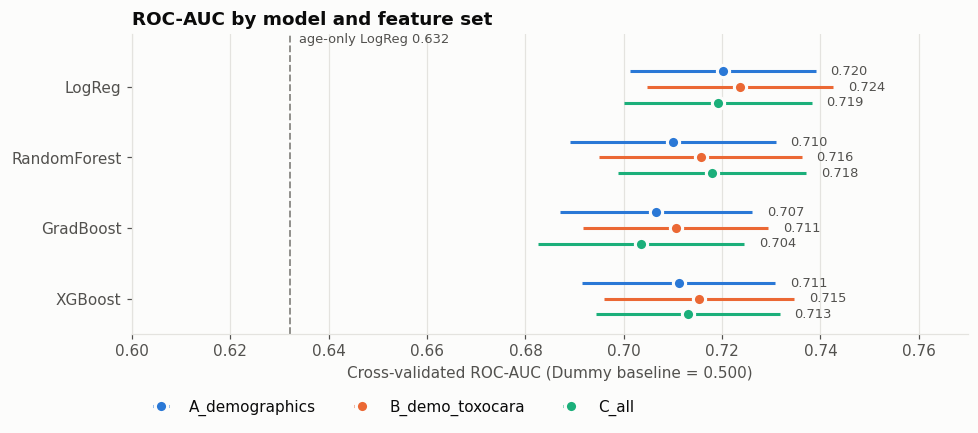

Mean CV ROC-AUC (rows = model, columns = feature set):


,A_demographics,B_demo_toxocara,C_all
LogReg,0.7202,0.7236,0.7192
RandomForest,0.7099,0.7156,0.7179
GradBoost,0.7066,0.7106,0.7035
XGBoost,0.7112,0.7154,0.7131


In [35]:
fig, ax = plt.subplots(figsize=(9, 4.2))
offsets = {'A_demographics': -0.22, 'B_demo_toxocara': 0.0, 'C_all': 0.22}
for s in THREE_SETS:
    for j, m in enumerate(REAL_MODELS):
        r = results[(m, s)]['roc_auc']
        ax.errorbar(r.mean(), j + offsets[s], xerr=r.std(), fmt='o', ms=8, color=SET_COLORS[s],
                    ecolor=SET_COLORS[s], elinewidth=2, capsize=0,
                    mec=SURFACE, mew=2, label=s if j == 0 else None)
        ax.text(r.mean() + r.std() + 0.003, j + offsets[s], f'{r.mean():.3f}', va='center',
                fontsize=8.5, color=INK_2)
age_auc = results[('LogReg', 'age_only')]['roc_auc'].mean()
ax.axvline(age_auc, color=REFERENCE, ls='--', lw=1.2)
ax.text(age_auc + 0.002, -0.62, f'age-only LogReg {age_auc:.3f}', color=INK_2, fontsize=8.5)
ax.set_yticks(range(len(REAL_MODELS)), REAL_MODELS)
ax.set_ylim(len(REAL_MODELS) - 0.5, -0.75)
ax.set_xlim(0.6, 0.77)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Cross-validated ROC-AUC (Dummy baseline = 0.500)')
ax.set_title('ROC-AUC by model and feature set')
ax.legend(loc='lower left', ncol=3, bbox_to_anchor=(0, -0.32))
plt.tight_layout()
plt.show()

wide = pd.DataFrame({s: {m: results[(m, s)]['roc_auc'].mean() for m in REAL_MODELS} for s in THREE_SETS}).round(4)
print('Mean CV ROC-AUC (rows = model, columns = feature set):')
display(wide)

---
## 4. Accuracy
The training script does not measure accuracy, and it never touches the test set. This section does both:

- **4.1 Cross-validated accuracy:** the same 15 folds as above, training set only.
- **4.2 Test-set accuracy:** each model is fitted once on the full training set (4,004 rows) and scored once on the held-out test set (1,002 rows).

Predictions use the default 0.5 probability threshold. Only about 15% of participants are positive. So "accuracy" alone is misleading: predicting everyone negative already gets about 85%. That is why balanced accuracy, sensitivity (recall on positives) and specificity are shown next to it.

### 4.1 Cross-validated accuracy (training set, 15 folds)

In [36]:
ACC_SCORING = {
    'accuracy': 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'sensitivity': 'recall',
    'precision': make_scorer(precision_score, zero_division=0),
}
cv_acc = {}
for m, s in EXPERIMENTS:
    cols = FEATURE_SETS[s]
    pipe = make_pipeline(make_preprocessor(cols), clone(MODELS[m]))
    cv = cross_validate(pipe, X_train[cols], y_train, cv=CV_SPLITS, scoring=ACC_SCORING)
    cv_acc[(m, s)] = {k: cv[f'test_{k}'] for k in ACC_SCORING}

cv_acc_table = pd.DataFrame([{
    'model': m, 'feature set': s,
    'accuracy mean': v['accuracy'].mean(), 'accuracy sd': v['accuracy'].std(),
    'balanced acc mean': v['balanced_accuracy'].mean(),
    'sensitivity mean': v['sensitivity'].mean(),
    'precision mean': v['precision'].mean(),
} for (m, s), v in cv_acc.items()]).round(4)
display(cv_acc_table)

print('Accuracy in every fold, per feature set:')
for s in THREE_SETS:
    f = pd.DataFrame({m: cv_acc[(m, s)]['accuracy'] for m in REAL_MODELS},
                     index=[f'repeat {k // 5 + 1}, fold {k % 5 + 1}' for k in range(15)]).round(4)
    f.loc['MEAN'] = f.mean().round(4)
    print(f'\n[{s}]')
    display(f)

,model,feature set,accuracy mean,accuracy sd,balanced acc mean,sensitivity mean,precision mean
0,Dummy,age_only,0.8501,0.0001,0.5000,0.0000,0.0000
1,LogReg,age_only,0.8501,0.0001,0.5000,0.0000,0.0000
2,LogReg,A_demographics,0.8483,0.0037,0.5209,0.0533,0.4551
3,RandomForest,A_demographics,0.8504,0.0028,0.5082,0.0194,0.5013
4,GradBoost,A_demographics,0.8494,0.0042,0.5332,0.0817,0.4891
5,XGBoost,A_demographics,0.8504,0.0041,0.5345,0.0833,0.5109
6,LogReg,B_demo_toxocara,0.8495,0.0035,0.5280,0.0689,0.4902
7,RandomForest,B_demo_toxocara,0.8502,0.0022,0.5081,0.0194,0.4748
8,GradBoost,B_demo_toxocara,0.8509,0.0048,0.5391,0.0939,0.5172
9,XGBoost,B_demo_toxocara,0.8520,0.0044,0.5391,0.0922,0.5398


Accuracy in every fold, per feature set:

[A_demographics]


,LogReg,RandomForest,GradBoost,XGBoost
"repeat 1, fold 1",0.8439,0.8527,0.8552,0.8552
"repeat 1, fold 2",0.8564,0.8527,0.8514,0.8489
"repeat 1, fold 3",0.8477,0.8552,0.8414,0.8464
"repeat 1, fold 4",0.8477,0.8464,0.8464,0.8502
"repeat 1, fold 5",0.8488,0.8488,0.8525,0.8500
"repeat 2, fold 1",0.8502,0.8514,0.8477,0.8552
"repeat 2, fold 2",0.8502,0.8527,0.8439,0.8514
"repeat 2, fold 3",0.8477,0.8477,0.8514,0.8439
"repeat 2, fold 4",0.8477,0.8489,0.8539,0.8577
"repeat 2, fold 5",0.8525,0.8488,0.8450,0.8462



[B_demo_toxocara]


,LogReg,RandomForest,GradBoost,XGBoost
"repeat 1, fold 1",0.8427,0.8539,0.8452,0.8527
"repeat 1, fold 2",0.8514,0.8489,0.8564,0.8502
"repeat 1, fold 3",0.8502,0.8539,0.8502,0.8502
"repeat 1, fold 4",0.8527,0.8464,0.8439,0.8514
"repeat 1, fold 5",0.8488,0.8500,0.8538,0.8512
"repeat 2, fold 1",0.8527,0.8527,0.8502,0.8539
"repeat 2, fold 2",0.8489,0.8527,0.8464,0.8539
"repeat 2, fold 3",0.8452,0.8477,0.8464,0.8439
"repeat 2, fold 4",0.8527,0.8514,0.8627,0.8639
"repeat 2, fold 5",0.8525,0.8488,0.8525,0.8512



[C_all]


,LogReg,RandomForest,GradBoost,XGBoost
"repeat 1, fold 1",0.8452,0.8489,0.8439,0.8502
"repeat 1, fold 2",0.8502,0.8489,0.8489,0.8527
"repeat 1, fold 3",0.8489,0.8502,0.8439,0.8527
"repeat 1, fold 4",0.8527,0.8502,0.8502,0.8539
"repeat 1, fold 5",0.8450,0.8500,0.8500,0.8475
"repeat 2, fold 1",0.8539,0.8502,0.8602,0.8602
"repeat 2, fold 2",0.8502,0.8502,0.8477,0.8564
"repeat 2, fold 3",0.8452,0.8477,0.8439,0.8464
"repeat 2, fold 4",0.8564,0.8502,0.8602,0.8627
"repeat 2, fold 5",0.8475,0.8488,0.8475,0.8438


### 4.2 Held-out test set: all models, all feature sets

In [37]:
def scores(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        'accuracy': accuracy_score(y_true, pred),
        'balanced accuracy': balanced_accuracy_score(y_true, pred),
        'sensitivity': tp / (tp + fn),
        'specificity': tn / (tn + fp),
        'precision': tp / (tp + fp) if (tp + fp) else 0.0,
        'ROC-AUC': roc_auc_score(y_true, proba),
        'PR-AUC': average_precision_score(y_true, proba),
        'Brier': brier_score_loss(y_true, proba),
        'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn,
    }

fitted, test_proba = {}, {}
for m, s in EXPERIMENTS:
    cols = FEATURE_SETS[s]
    pipe = make_pipeline(make_preprocessor(cols), clone(MODELS[m])).fit(X_train[cols], y_train)
    fitted[(m, s)] = pipe
    test_proba[(m, s)] = pipe.predict_proba(X_test[cols])[:, 1]

test_table = pd.DataFrame([{'model': m, 'feature set': s, **scores(y_test, p)}
                           for (m, s), p in test_proba.items()])
display(test_table.round(4))
majority_acc = 1 - y_test.mean()
print(f'Test set: {len(y_test):,} rows, {int(y_test.sum())} positive ({y_test.mean():.1%}).')
print(f'Always-negative accuracy on this test set: {majority_acc:.1%}')

,model,feature set,accuracy,balanced accuracy,sensitivity,specificity,precision,ROC-AUC,PR-AUC,Brier,TP,FP,TN,FN
0,Dummy,age_only,0.8503,0.5000,0.0000,1.0000,0.0000,0.5000,0.1497,0.1273,0,0,852,150
1,LogReg,age_only,0.8503,0.5000,0.0000,1.0000,0.0000,0.6412,0.2156,0.1235,0,0,852,150
2,LogReg,A_demographics,0.8513,0.5281,0.0667,0.9894,0.5263,0.7001,0.3164,0.1177,10,9,843,140
3,RandomForest,A_demographics,0.8523,0.5122,0.0267,0.9977,0.6667,0.6993,0.3134,0.1178,4,2,850,146
4,GradBoost,A_demographics,0.8503,0.5330,0.0800,0.9859,0.5000,0.6852,0.2881,0.1208,12,12,840,138
5,XGBoost,A_demographics,0.8533,0.5347,0.0800,0.9894,0.5714,0.6977,0.3015,0.1192,12,9,843,138
6,LogReg,B_demo_toxocara,0.8533,0.5347,0.0800,0.9894,0.5714,0.7126,0.3325,0.1162,12,9,843,138
7,RandomForest,B_demo_toxocara,0.8523,0.5149,0.0333,0.9965,0.6250,0.7090,0.3292,0.1168,5,3,849,145
8,GradBoost,B_demo_toxocara,0.8453,0.5190,0.0533,0.9847,0.3810,0.6994,0.2947,0.1198,8,13,839,142
9,XGBoost,B_demo_toxocara,0.8483,0.5208,0.0533,0.9883,0.4444,0.7081,0.3100,0.1181,8,10,842,142


Test set: 1,002 rows, 150 positive (15.0%).
Always-negative accuracy on this test set: 85.0%


### 4.3 Test-set results for each of the three feature sets
Each set gets its own table. The confusion matrix and ROC curve below use that set's best model, picked by **cross-validated** ROC-AUC (Section 3), not by test results.

In [38]:
best_per_set = {s: max(REAL_MODELS, key=lambda m: results[(m, s)]['roc_auc'].mean()) for s in THREE_SETS}
for s in THREE_SETS:
    print(f'===== Feature set {s} (best by CV: {best_per_set[s]}) =====')
    display(test_table[test_table['feature set'] == s].drop(columns='feature set').round(4).reset_index(drop=True))
    pred = (test_proba[(best_per_set[s], s)] >= 0.5).astype(int)
    print(f'Classification report, {best_per_set[s]} on {s} (threshold 0.5):')
    print(classification_report(y_test, pred, target_names=['negative (0)', 'positive (1)'],
                                digits=3, zero_division=0))

===== Feature set A_demographics (best by CV: LogReg) =====


,model,accuracy,balanced accuracy,sensitivity,specificity,precision,ROC-AUC,PR-AUC,Brier,TP,FP,TN,FN
0,LogReg,0.8513,0.5281,0.0667,0.9894,0.5263,0.7001,0.3164,0.1177,10,9,843,140
1,RandomForest,0.8523,0.5122,0.0267,0.9977,0.6667,0.6993,0.3134,0.1178,4,2,850,146
2,GradBoost,0.8503,0.5330,0.0800,0.9859,0.5000,0.6852,0.2881,0.1208,12,12,840,138
3,XGBoost,0.8533,0.5347,0.0800,0.9894,0.5714,0.6977,0.3015,0.1192,12,9,843,138


Classification report, LogReg on A_demographics (threshold 0.5):
              precision    recall  f1-score   support

negative (0)      0.858     0.989     0.919       852
positive (1)      0.526     0.067     0.118       150

    accuracy                          0.851      1002
   macro avg      0.692     0.528     0.519      1002
weighted avg      0.808     0.851     0.799      1002

===== Feature set B_demo_toxocara (best by CV: LogReg) =====


,model,accuracy,balanced accuracy,sensitivity,specificity,precision,ROC-AUC,PR-AUC,Brier,TP,FP,TN,FN
0,LogReg,0.8533,0.5347,0.0800,0.9894,0.5714,0.7126,0.3325,0.1162,12,9,843,138
1,RandomForest,0.8523,0.5149,0.0333,0.9965,0.6250,0.7090,0.3292,0.1168,5,3,849,145
2,GradBoost,0.8453,0.5190,0.0533,0.9847,0.3810,0.6994,0.2947,0.1198,8,13,839,142
3,XGBoost,0.8483,0.5208,0.0533,0.9883,0.4444,0.7081,0.3100,0.1181,8,10,842,142


Classification report, LogReg on B_demo_toxocara (threshold 0.5):
              precision    recall  f1-score   support

negative (0)      0.859     0.989     0.920       852
positive (1)      0.571     0.080     0.140       150

    accuracy                          0.853      1002
   macro avg      0.715     0.535     0.530      1002
weighted avg      0.816     0.853     0.803      1002

===== Feature set C_all (best by CV: LogReg) =====


,model,accuracy,balanced accuracy,sensitivity,specificity,precision,ROC-AUC,PR-AUC,Brier,TP,FP,TN,FN
0,LogReg,0.8563,0.5392,0.0867,0.9918,0.6500,0.7124,0.3367,0.1159,13,7,845,137
1,RandomForest,0.8493,0.4994,0.0000,0.9988,0.0000,0.6932,0.3103,0.1180,0,1,851,150
2,GradBoost,0.8513,0.5335,0.0800,0.9871,0.5217,0.6956,0.3110,0.1184,12,11,841,138
3,XGBoost,0.8523,0.5369,0.0867,0.9871,0.5417,0.6991,0.3137,0.1180,13,11,841,137


Classification report, LogReg on C_all (threshold 0.5):
              precision    recall  f1-score   support

negative (0)      0.860     0.992     0.921       852
positive (1)      0.650     0.087     0.153       150

    accuracy                          0.856      1002
   macro avg      0.755     0.539     0.537      1002
weighted avg      0.829     0.856     0.806      1002



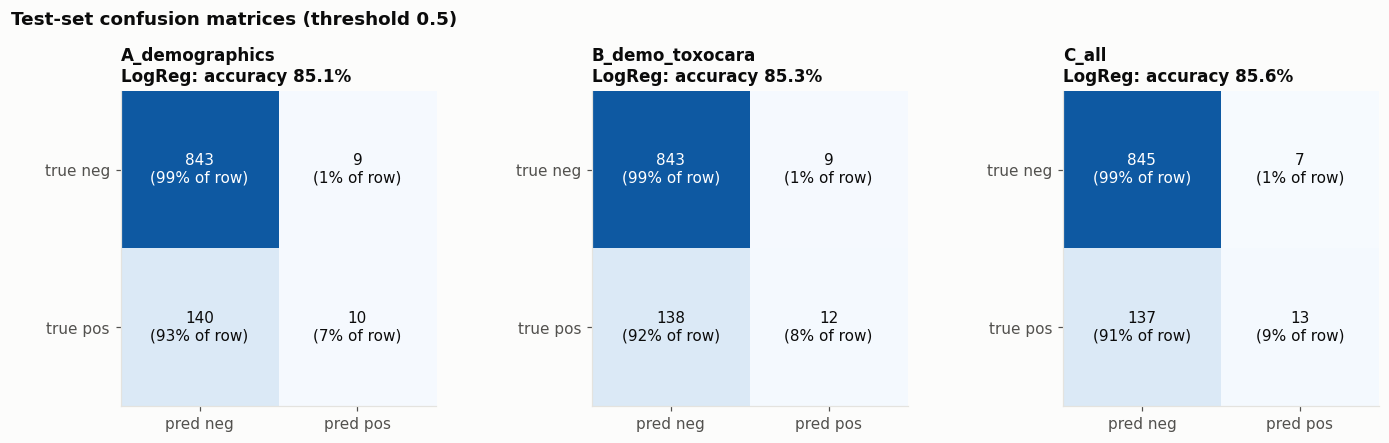

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, s in zip(axes, THREE_SETS):
    m = best_per_set[s]
    cm = confusion_matrix(y_test, (test_proba[(m, s)] >= 0.5).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=len(y_test))
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f'{v}\n({v / cm[i].sum():.0%} of row)', ha='center', va='center',
                color='white' if v > len(y_test) * 0.5 else INK, fontsize=10)
    ax.set_xticks([0, 1], ['pred neg', 'pred pos'])
    ax.set_yticks([0, 1], ['true neg', 'true pos'])
    ax.grid(False)
    acc = np.trace(cm) / cm.sum()
    ax.set_title(f'{s}\n{m}: accuracy {acc:.1%}', fontsize=11)
fig.suptitle('Test-set confusion matrices (threshold 0.5)', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

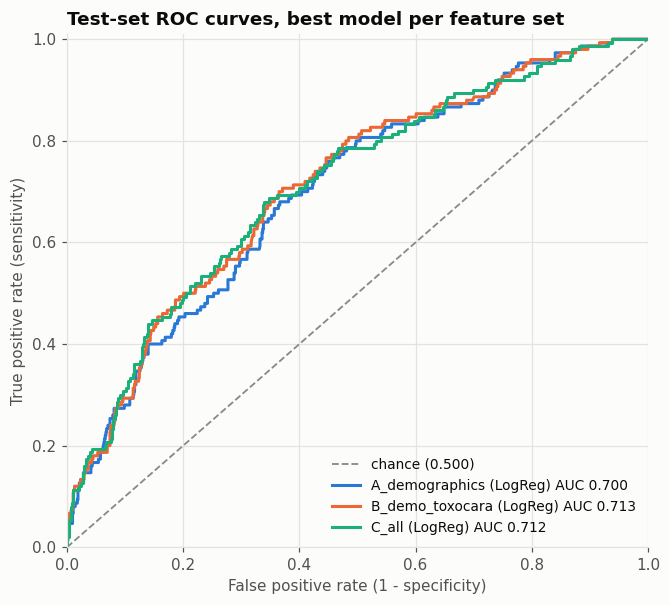

In [40]:
fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.plot([0, 1], [0, 1], ls='--', color=REFERENCE, lw=1.2, label='chance (0.500)')
for s in THREE_SETS:
    m = best_per_set[s]
    fpr, tpr, _ = roc_curve(y_test, test_proba[(m, s)])
    ax.plot(fpr, tpr, lw=2, color=SET_COLORS[s],
            label=f'{s} ({m}) AUC {roc_auc_score(y_test, test_proba[(m, s)]):.3f}')
ax.set_xlabel('False positive rate (1 - specificity)')
ax.set_ylabel('True positive rate (sensitivity)')
ax.set_title('Test-set ROC curves, best model per feature set')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

### 4.4 Accuracy at a threshold that fits the class balance
With only 15% positives, a 0.5 threshold makes the models flag almost nobody, so accuracy mostly measures how many negatives there are. The table below also uses a threshold equal to the **training-set positive rate**. That value comes from the training data only, so the test set is not used to tune it. This shows the trade-off: more positives caught, lower raw accuracy.

In [41]:
prev_threshold = y_train.mean()
print(f'Threshold = training positive rate = {prev_threshold:.3f}\n')
rows = []
for s in THREE_SETS:
    for m in REAL_MODELS:
        a = scores(y_test, test_proba[(m, s)], 0.5)
        b = scores(y_test, test_proba[(m, s)], prev_threshold)
        rows.append({'feature set': s, 'model': m,
                     'acc @0.5': a['accuracy'], 'sens @0.5': a['sensitivity'], 'spec @0.5': a['specificity'],
                     f'acc @{prev_threshold:.2f}': b['accuracy'], f'sens @{prev_threshold:.2f}': b['sensitivity'],
                     f'spec @{prev_threshold:.2f}': b['specificity'],
                     f'bal acc @{prev_threshold:.2f}': b['balanced accuracy']})
display(pd.DataFrame(rows).round(4))

Threshold = training positive rate = 0.150



,feature set,model,acc @0.5,sens @0.5,spec @0.5,acc @0.15,sens @0.15,spec @0.15,bal acc @0.15
0,A_demographics,LogReg,0.8513,0.0667,0.9894,0.6637,0.5867,0.6772,0.6319
1,A_demographics,RandomForest,0.8523,0.0267,0.9977,0.6277,0.7067,0.6138,0.6603
2,A_demographics,GradBoost,0.8503,0.0800,0.9859,0.6417,0.6467,0.6408,0.6438
3,A_demographics,XGBoost,0.8533,0.0800,0.9894,0.6377,0.6400,0.6373,0.6387
4,B_demo_toxocara,LogReg,0.8533,0.0800,0.9894,0.6737,0.5933,0.6878,0.6406
5,B_demo_toxocara,RandomForest,0.8523,0.0333,0.9965,0.6367,0.7267,0.6209,0.6738
6,B_demo_toxocara,GradBoost,0.8453,0.0533,0.9847,0.6427,0.6533,0.6408,0.6471
7,B_demo_toxocara,XGBoost,0.8483,0.0533,0.9883,0.6567,0.6467,0.6585,0.6526
8,C_all,LogReg,0.8563,0.0867,0.9918,0.6747,0.6200,0.6843,0.6521
9,C_all,RandomForest,0.8493,0.0000,0.9988,0.6248,0.7200,0.6080,0.6640


### 4.5 ROC curves and AUC for every model
An ROC curve shows, for every possible threshold, the share of positives caught (sensitivity, y) against the share of negatives wrongly flagged (1 - specificity, x). **AUC** is the area under that curve: 0.5 is random guessing, 1.0 is perfect ranking. Unlike accuracy, AUC does not depend on the threshold or on the 15% class balance.

One panel per model; colours are the three feature sets (same colours as above). The grey dashed curve is the age-only LogReg baseline and the dotted diagonal is chance.

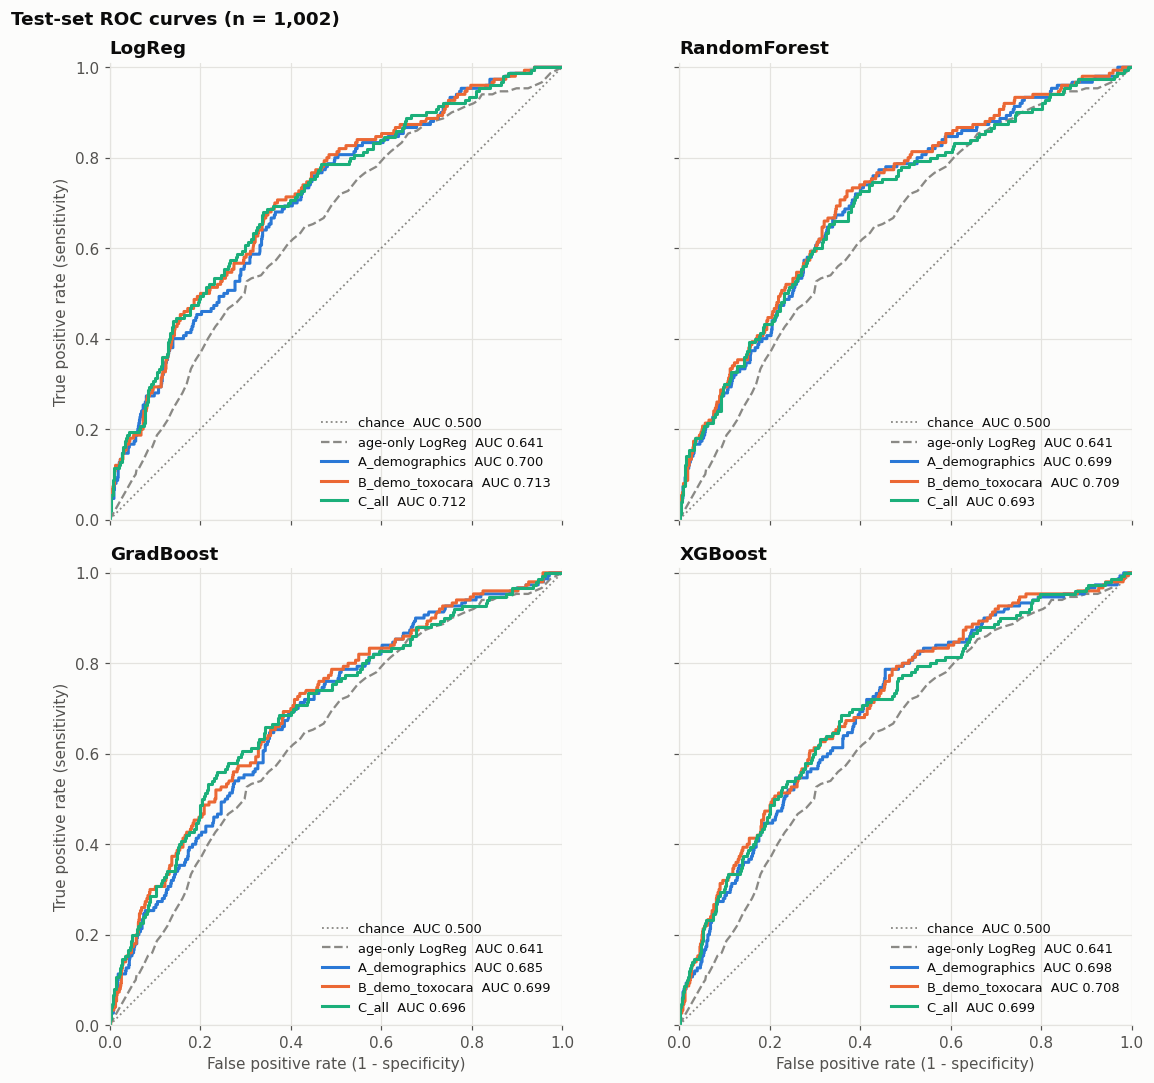

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10), sharex=True, sharey=True)
fpr_age, tpr_age, _ = roc_curve(y_test, test_proba[('LogReg', 'age_only')])
auc_age = roc_auc_score(y_test, test_proba[('LogReg', 'age_only')])
for ax, m in zip(axes.flat, REAL_MODELS):
    ax.plot([0, 1], [0, 1], ls=':', color=REFERENCE, lw=1.2, label='chance  AUC 0.500')
    ax.plot(fpr_age, tpr_age, ls='--', color=REFERENCE, lw=1.5, label=f'age-only LogReg  AUC {auc_age:.3f}')
    for s in THREE_SETS:
        fpr, tpr, _ = roc_curve(y_test, test_proba[(m, s)])
        ax.plot(fpr, tpr, lw=2, color=SET_COLORS[s],
                label=f'{s}  AUC {roc_auc_score(y_test, test_proba[(m, s)]):.3f}')
    ax.set_title(m)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.01)
    ax.set_aspect('equal')
    ax.legend(loc='lower right', fontsize=8.5)
for ax in axes[1]:
    ax.set_xlabel('False positive rate (1 - specificity)')
for ax in axes[:, 0]:
    ax.set_ylabel('True positive rate (sensitivity)')
fig.suptitle('Test-set ROC curves (n = 1,002)', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

**AUC table.** Cross-validated AUC (15 folds, training set) next to test-set AUC with a 95% bootstrap confidence interval (1,000 resamples of the test set). The intervals are about ±0.045 wide, so differences of 0.01-0.02 between models are within noise. This matches the H2-H4 tests.

In [43]:
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot_idx = []
while len(boot_idx) < 1000:
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if 0 < y_arr[idx].sum() < len(idx):      # both classes needed for an AUC
        boot_idx.append(idx)

auc_rows = []
for (m, s), p in test_proba.items():
    boots = np.array([roc_auc_score(y_arr[i], p[i]) for i in boot_idx])
    auc_rows.append({
        'model': m, 'feature set': s,
        'CV AUC mean': results[(m, s)]['roc_auc'].mean(),
        'CV AUC sd': results[(m, s)]['roc_auc'].std(),
        'test AUC': roc_auc_score(y_arr, p),
        'test AUC 95% CI low': np.percentile(boots, 2.5),
        'test AUC 95% CI high': np.percentile(boots, 97.5),
    })
auc_table = pd.DataFrame(auc_rows).round(3)
display(auc_table)

,model,feature set,CV AUC mean,CV AUC sd,test AUC,test AUC 95% CI low,test AUC 95% CI high
0,Dummy,age_only,0.500,0.000,0.500,0.500,0.500
1,LogReg,age_only,0.632,0.022,0.641,0.595,0.687
2,LogReg,A_demographics,0.720,0.019,0.700,0.657,0.747
3,RandomForest,A_demographics,0.710,0.021,0.699,0.658,0.747
4,GradBoost,A_demographics,0.707,0.019,0.685,0.640,0.735
5,XGBoost,A_demographics,0.711,0.020,0.698,0.654,0.748
6,LogReg,B_demo_toxocara,0.724,0.019,0.713,0.671,0.759
7,RandomForest,B_demo_toxocara,0.716,0.021,0.709,0.666,0.758
8,GradBoost,B_demo_toxocara,0.711,0.019,0.699,0.656,0.750
9,XGBoost,B_demo_toxocara,0.715,0.019,0.708,0.665,0.758


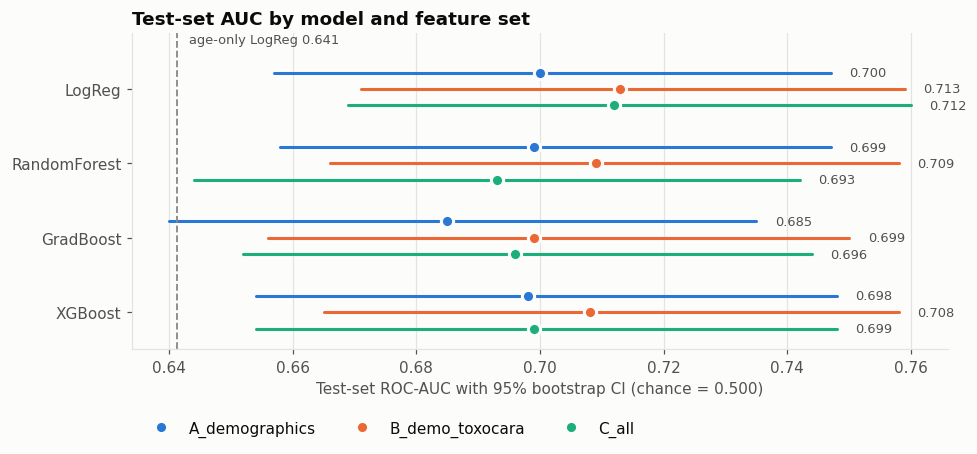

In [44]:
fig, ax = plt.subplots(figsize=(9, 4.4))
for s in THREE_SETS:
    for j, m in enumerate(REAL_MODELS):
        r = auc_table[(auc_table['model'] == m) & (auc_table['feature set'] == s)].iloc[0]
        y_pos = j + offsets[s]
        ax.plot([r['test AUC 95% CI low'], r['test AUC 95% CI high']], [y_pos, y_pos],
                color=SET_COLORS[s], lw=2, solid_capstyle='round')
        ax.plot(r['test AUC'], y_pos, 'o', ms=8, color=SET_COLORS[s], mec=SURFACE, mew=2,
                label=s if j == 0 else None)
        ax.text(r['test AUC 95% CI high'] + 0.003, y_pos, f"{r['test AUC']:.3f}", va='center',
                fontsize=8.5, color=INK_2)
ax.axvline(auc_age, color=REFERENCE, ls='--', lw=1.2)
ax.text(auc_age + 0.002, -0.62, f'age-only LogReg {auc_age:.3f}', color=INK_2, fontsize=8.5)
ax.set_yticks(range(len(REAL_MODELS)), REAL_MODELS)
ax.set_ylim(len(REAL_MODELS) - 0.5, -0.75)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Test-set ROC-AUC with 95% bootstrap CI (chance = 0.500)')
ax.set_title('Test-set AUC by model and feature set')
ax.legend(loc='lower left', ncol=3, bbox_to_anchor=(0, -0.32))
plt.tight_layout()
plt.show()

---
## 5. Total accuracy summary
The headline model is the one with the best mean **cross-validated** ROC-AUC across all models and feature sets. It is chosen without looking at the test set, then scored once on the 1,002 held-out participants.

In [45]:
real_experiments = [(m, s) for m, s in EXPERIMENTS if s in THREE_SETS]
best_m, best_s = max(real_experiments, key=lambda k: results[k]['roc_auc'].mean())
best = scores(y_test, test_proba[(best_m, best_s)])
best_cv = cv_acc[(best_m, best_s)]

line = '=' * 64
print(line)
print('  TOTAL ACCURACY: current model on the held-out test set')
print(line)
print(f'  Selected model        : {best_m} on feature set {best_s}')
print(f'  Selected because      : best mean CV ROC-AUC ({results[(best_m, best_s)]["roc_auc"].mean():.3f})')
print(f'  Test rows             : {len(y_test):,} ({int(y_test.sum())} positive)')
print(line)
print(f'  ACCURACY (test)       : {best["accuracy"]:.1%}   ({best["TP"] + best["TN"]} of {len(y_test)} correct)')
print(f'  Accuracy (CV, train)  : {best_cv["accuracy"].mean():.1%} +/- {best_cv["accuracy"].std():.1%}')
print(f'  Always-negative       : {majority_acc:.1%}')
print(f'  Balanced accuracy     : {best["balanced accuracy"]:.1%}')
print(f'  Sensitivity           : {best["sensitivity"]:.1%}   ({best["TP"]} of {best["TP"] + best["FN"]} positives found)')
print(f'  Specificity           : {best["specificity"]:.1%}')
print(f'  ROC-AUC (test)        : {best["ROC-AUC"]:.3f}')
print(f'  PR-AUC (test)         : {best["PR-AUC"]:.3f}   (random = {y_test.mean():.3f})')
print(line)

print('\nTest accuracy for every model x feature set (threshold 0.5):')
acc_grid = test_table[test_table['feature set'].isin(THREE_SETS)].pivot(
    index='model', columns='feature set', values='accuracy').loc[REAL_MODELS, THREE_SETS]
acc_grid.loc['MEAN over models'] = acc_grid.mean()
display((acc_grid * 100).round(2).astype(str) + ' %')

print('Test ROC-AUC for every model x feature set:')
auc_grid = test_table[test_table['feature set'].isin(THREE_SETS)].pivot(
    index='model', columns='feature set', values='ROC-AUC').loc[REAL_MODELS, THREE_SETS]
display(auc_grid.round(4))

  TOTAL ACCURACY: current model on the held-out test set
  Selected model        : LogReg on feature set B_demo_toxocara
  Selected because      : best mean CV ROC-AUC (0.724)
  Test rows             : 1,002 (150 positive)
  ACCURACY (test)       : 85.3%   (855 of 1002 correct)
  Accuracy (CV, train)  : 84.9% +/- 0.4%
  Always-negative       : 85.0%
  Balanced accuracy     : 53.5%
  Sensitivity           : 8.0%   (12 of 150 positives found)
  Specificity           : 98.9%
  ROC-AUC (test)        : 0.713
  PR-AUC (test)         : 0.333   (random = 0.150)

Test accuracy for every model x feature set (threshold 0.5):


feature set,A_demographics,B_demo_toxocara,C_all
model,,,
LogReg,85.13 %,85.33 %,85.63 %
RandomForest,85.23 %,85.23 %,84.93 %
GradBoost,85.03 %,84.53 %,85.13 %
XGBoost,85.33 %,84.83 %,85.23 %
MEAN over models,85.18 %,84.98 %,85.23 %


Test ROC-AUC for every model x feature set:


feature set,A_demographics,B_demo_toxocara,C_all
model,,,
LogReg,0.7001,0.7126,0.7124
RandomForest,0.6993,0.7090,0.6932
GradBoost,0.6852,0.6994,0.6956
XGBoost,0.6977,0.7081,0.6991


### How to read these numbers
- **Accuracy is about the same for every model, and close to the always-negative score.** At a 0.5 threshold the models predict "negative" for nearly everyone, because only about 15% of participants are positive. The overall accuracy figure is honest, but most of it comes from the class balance, not from the features.
- **ROC-AUC (about 0.72) is the more informative number.** It measures how well the model ranks positives above negatives, regardless of threshold. All real models clearly beat the baselines (H1). Complex models do not beat logistic regression (H2). Toxocara (B) and behaviour/health (C) add little over demographics (H3, H4).
- **To catch positives, lower the threshold** (Section 4.4). Sensitivity rises a lot and raw accuracy falls. The right threshold depends on how the model would be used, e.g. screening vs. confirmation.